# IEEE-CIS Fraud Detection: Tuning Models with Categorical Levels
## DSCI 598 Capstone, Week 5
### Ben Miller

Companion notebooks: `bm-fraud-categorical-tests` (this week's level tests), `bm-fraud-categorical-submission` (this week's submission), and `bm-fraud-numeric-tuning` (Week 4).

# Part 2: Numerical features plus the predictive categorical levels
> Use statistical tests to determine which levels of each categorical variable are most predictive. Keep only these levels and discard the rest. Again, consider logistic regression, decision tree, random forest, and gradient boosted tree models, and use cross-validation for hyperparameter tuning. Submit the predictions generated by the optimal model found.

### Decisions for this week

1. **Level selection rules.** A level is tested only if it has at least **500** training transactions. It's kept if it's still significant after a **Benjamini–Hochberg** correction at 5% across every level tested, its fraud rate is at least **1.5×** the overall rate or at most **0.67×** of it, and it ranks in its column's top **25** by chi-square statistic. Missing values count as their own level. Levels that aren't kept are grouped into one "other" column per categorical column, so no rows are lost.
2. **Selection is fit inside each fold.** Each cross-validation fold runs the tests on its own training rows only. If the tests used all the training data, each fold's validation rows would help choose the levels and the scores would look better than they really are.
3. **The same search as Week 4.** The same four time-ordered folds, metrics and number of settings per model (8, 12, 6 and 10), so any change in score comes from the categorical features.

### Imports, seeds and constants

In [1]:
import os
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Kaggle mounts the competition files here (read-only)
DATA_DIR = '/kaggle/input/competitions/ieee-fraud-detection'

# Column names used throughout
ID_COLUMN = 'TransactionID'
TARGET = 'isFraud'
TIME_COLUMN = 'TransactionDT'      # seconds from an undisclosed starting point, not a real timestamp
AMOUNT_COLUMN = 'TransactionAmt'
import gc   # frees memory between folds

# Numerical features (the decision above): measurement-like columns only
NUMERIC_FAMILIES = ['C', 'D', 'V', 'dist']   # counts, time deltas, Vesta features, distances
NUMERIC_IDENTITY_COLUMNS = [f'id_{number:02d}' for number in range(1, 12)]  # id_01-id_11 are measurements; id_12 on are categories
OTHER_NUMERIC_COLUMNS = [AMOUNT_COLUMN, 'has_identity']

# V-column reduction
CORRELATION_SAMPLE_SIZE = 100_000   # rows used to measure correlations (feature selection only, not tuning)
HIGH_CORRELATION = 0.95             # V columns more correlated than this with one already kept are dropped

# Model settings that aren't tuned
TREE_MISSING_VALUE = -999      # scikit-learn trees get missing values replaced by this; it sits below every real value
LOGREG_MAX_ITER = 2000
LIGHTGBM_MAX_ROUNDS = 3000     # upper limit; early stopping picks the real number
EARLY_STOPPING_ROUNDS = 100

# Categorical level selection. These rules are fit on training rows only.
MIN_LEVEL_COUNT = 500        # levels with fewer training transactions aren't tested; their fraud rate is too noisy to trust
FDR_ALPHA = 0.05             # Benjamini-Hochberg false discovery rate across every level tested
MIN_RATE_RATIO = 1.5         # a kept level's fraud rate is at least 1.5x the overall rate, or at most 1/1.5 of it
MAX_LEVELS_PER_COLUMN = 25   # strongest levels kept per column, so no single column adds hundreds of features
MISSING_LABEL = 'missing'    # missing values are a level of their own, since a blank field can be a signal
OTHER_LABEL = 'other'        # every level that isn't kept is grouped here, so no rows are lost

# Cross-validation (the same as Week 4)
N_FOLDS = 4
REVIEW_RATE = 0.01
RESULTS_DIR = '.'    # on Kaggle this is /kaggle/working, which keeps files as notebook output

# Earlier results on the same last-20% split
WEEK3_BASELINE_AUC = 0.9227   # LightGBM on every column, integer-encoded
WEEK4_BEST_AUC = 0.8960       # tuned LightGBM, numerical features only

# The same search as Week 4
CANDIDATES_PER_MODEL = {
    'logistic_regression': 8,
    'decision_tree': 12,
    'random_forest': 6,
    'lightgbm': 10,
}

SEARCH_SPACES = {
    'logistic_regression': {
        'C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
        'class_weight': [None, 'balanced'],
    },
    'decision_tree': {
        'max_depth': [4, 6, 8, 10, 12, 15, 20],
        'min_samples_leaf': [10, 50, 100, 250, 500],
        'class_weight': [None, 'balanced'],
    },
    'random_forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [12, 16, 20, 25],
        'min_samples_leaf': [1, 5, 20],
        'max_features': ['sqrt', 'log2'],
        'max_samples': [0.5, 0.8],
        'class_weight': [None, 'balanced_subsample'],
    },
    'lightgbm': {
        'num_leaves': [31, 63, 127, 255],
        'learning_rate': [0.02, 0.05, 0.1],
        'colsample_bytree': [0.3, 0.5, 0.7],
        'subsample': [0.7, 0.8, 0.9],
        'min_child_samples': [20, 50, 100],
        'reg_lambda': [0.0, 1.0, 5.0],
    },
}

sns.set_theme(style='whitegrid')

### Data-loading functions

In [2]:
def downcast_numeric_columns(frame):
    """
    Shrink float64 columns to float32 and integer columns to the smallest type that fits.
    The raw tables need several GB as float64; float32 roughly halves that, and tree
    models don't need the extra precision.
    """
    smaller_types = {}
    for column in frame.columns:
        if pd.api.types.is_float_dtype(frame[column]):
            smaller_types[column] = 'float32'
        elif pd.api.types.is_integer_dtype(frame[column]):
            smallest_fit = pd.to_numeric(frame[column], downcast='integer')
            smaller_types[column] = smallest_fit.dtype

    # one astype call for every column; assigning hundreds of columns one at a time fragments the DataFrame
    return frame.astype(smaller_types)


def standardize_identity_columns(identity):
    """
    Rename test_identity's 'id-01' style columns to train's 'id_01' spelling.
    The competition files use a hyphen in test and an underscore in train, so without
    this every identity feature would silently be missing in test after the merge.
    """
    renamed_columns = {}
    for column in identity.columns:
        if column.startswith('id-'):
            renamed_columns[column] = column.replace('id-', 'id_')
    return identity.rename(columns=renamed_columns)


def load_table(file_name):
    """One competition CSV, with its numeric columns downcast."""
    frame = pd.read_csv(os.path.join(DATA_DIR, file_name))
    return downcast_numeric_columns(frame)


def merge_identity(transactions, identity):
    """
    Left-join identity onto transactions by TransactionID, and flag which rows had a match.
    Only some transactions have identity data, so a left join keeps every transaction and
    leaves the identity columns missing for the rest.
    """
    # mark identity rows before the merge; transactions without a match end up missing, then 0
    flagged_identity = identity.assign(has_identity=1)
    merged = transactions.merge(flagged_identity, on=ID_COLUMN, how='left')
    merged['has_identity'] = merged['has_identity'].fillna(0).astype('int8')
    return merged


def load_split(split_name):
    """The merged transaction + identity table for 'train' or 'test'."""
    transactions = load_table(f'{split_name}_transaction.csv')
    identity = standardize_identity_columns(load_table(f'{split_name}_identity.csv'))
    return merge_identity(transactions, identity)


def memory_mb(frame):
    """How much memory a DataFrame uses, in megabytes."""
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

### Load the training data, ordered by time

In [3]:
train = load_split('train')
train = train.sort_values(TIME_COLUMN).reset_index(drop=True)
print(f'train: {train.shape[0]:,} rows x {train.shape[1]} columns, {memory_mb(train):,.0f} MB')

train: 590,540 rows x 435 columns, 1,604 MB


### Feature functions (from Week 4)

In [4]:
def column_family(column):
    """The feature family a column belongs to, from its name: 'V' for V1-V339, 'dist' for dist1-dist2, and so on."""
    if column.startswith('id_'):
        return 'id'
    return column.rstrip('0123456789')  # 'V258' -> 'V', 'dist1' -> 'dist'


def numeric_feature_columns(frame):
    """
    The measurement-like columns: amount, the identity flag, C, D, V, dist and id_01-id_11.
    Columns that hold category codes stored as numbers (card1-card6, addr1, addr2, id_12 on)
    are left out on purpose, along with the text columns.
    """
    features = []
    for column in frame.columns:
        if column_family(column) in NUMERIC_FAMILIES:
            features.append(column)
        elif column in NUMERIC_IDENTITY_COLUMNS or column in OTHER_NUMERIC_COLUMNS:
            features.append(column)
    return features


def select_uncorrelated_columns(frame, columns, threshold, sample_size):
    """
    Keep one column from each group of near-duplicates, scanning the columns in order.
    A column is dropped when its absolute correlation with a column already kept is above threshold.
    Correlations come from a random sample of rows: plenty to measure a correlation, and much faster than all rows.
    """
    sample = frame[columns].sample(n=min(sample_size, len(frame)), random_state=SEED)
    correlation = sample.corr().abs()
    kept_columns = []
    for column in columns:
        is_near_duplicate = False
        for kept_column in kept_columns:
            if correlation.loc[column, kept_column] > threshold:
                is_near_duplicate = True
                break
        if not is_near_duplicate:
            kept_columns.append(column)
    return kept_columns


def model_feature_columns(frame):
    """The numerical features with redundant V columns removed."""
    numeric_columns = numeric_feature_columns(frame)
    v_columns = []
    other_columns = []
    for column in numeric_columns:
        if column_family(column) == 'V':
            v_columns.append(column)
        else:
            other_columns.append(column)
    kept_v_columns = select_uncorrelated_columns(frame, v_columns, HIGH_CORRELATION, CORRELATION_SAMPLE_SIZE)
    return other_columns + kept_v_columns

### Categorical level functions (from the level tests notebook)

In [5]:
def categorical_feature_columns(frame, numeric_columns):
    """Every column that isn't numerical, the ID, the target or the raw time: the columns held back in Week 4."""
    excluded = set(numeric_columns) | {ID_COLUMN, TARGET, TIME_COLUMN}
    categorical_columns = []
    for column in frame.columns:
        if column not in excluded:
            categorical_columns.append(column)
    return categorical_columns


def categorical_labels(series):
    """
    One categorical column as text labels, with missing values labeled 'missing'.
    Number codes are converted to float first, so a code reads the same in train and test
    (1234.0 in both, not 1234 in one file and 1234.0 in the other).
    """
    is_missing = series.isna()
    if pd.api.types.is_numeric_dtype(series):
        series = series.astype('float64')
    labels = series.astype(str)
    labels[is_missing] = MISSING_LABEL
    return labels.astype('category')


def categorical_label_frame(frame, categorical_columns):
    """
    Text labels for every categorical column, built once up front.
    This step doesn't look at the target, so building it on all rows can't leak anything.
    """
    labels = {}
    for column in categorical_columns:
        labels[column] = categorical_labels(frame[column])
    return pd.DataFrame(labels, index=frame.index)


def test_levels(labels, target):
    """
    A chi-square test for every level of one column that has at least MIN_LEVEL_COUNT rows.
    Each test uses a 2x2 table (in this level or not, fraud or not) to ask whether the level's
    fraud rate differs from the rate in all the other rows.
    """
    target = np.asarray(target).astype('int64')   # isFraud is stored as int8, which would overflow in the counts below
    total_rows = len(target)
    total_fraud = int(target.sum())
    overall_rate = total_fraud / total_rows
    level_rows = labels.value_counts()
    level_fraud = pd.Series(target, index=labels.index).groupby(labels, observed=True).sum()

    rows = []
    for level, rows_in_level in level_rows.items():
        rows_in_level = int(rows_in_level)
        if rows_in_level < MIN_LEVEL_COUNT or rows_in_level == total_rows:
            continue  # too rare to trust, or the column has only one level here, so there's nothing to compare
        fraud_in_level = int(level_fraud[level])
        table = [
            [fraud_in_level, rows_in_level - fraud_in_level],
            [total_fraud - fraud_in_level, (total_rows - rows_in_level) - (total_fraud - fraud_in_level)],
        ]
        chi_square, p_value, _, _ = chi2_contingency(table)
        level_rate = fraud_in_level / rows_in_level
        rows.append({
            'level': level,
            'transactions': int(rows_in_level),
            'fraud_rate': level_rate,
            'rate_ratio': level_rate / overall_rate,
            'chi_square': chi_square,
            'p_value': p_value,
        })
    return pd.DataFrame(rows)


def find_predictive_levels(label_frame, target):
    """
    Test every level of every categorical column, then mark which levels to keep. A level is kept when it
    (1) is still significant after the Benjamini-Hochberg correction across all tests,
    (2) has a fraud rate at least MIN_RATE_RATIO times the overall rate, or at most 1/MIN_RATE_RATIO of it, and
    (3) ranks in its column's top MAX_LEVELS_PER_COLUMN by chi-square statistic.
    Returns one row per level tested.
    """
    column_reports = []
    for column in label_frame.columns:
        column_report = test_levels(label_frame[column], target)
        if len(column_report) > 0:
            column_report.insert(0, 'column', column)
            column_reports.append(column_report)
    if not column_reports:
        return pd.DataFrame(columns=['column', 'level', 'transactions', 'fraud_rate', 'rate_ratio',
                                     'chi_square', 'p_value', 'adjusted_p_value', 'kept'])

    report = pd.concat(column_reports, ignore_index=True)
    significant, adjusted_p_values, _, _ = multipletests(report['p_value'], alpha=FDR_ALPHA, method='fdr_bh')
    report['adjusted_p_value'] = adjusted_p_values
    report['significant'] = significant

    much_higher = report['rate_ratio'] >= MIN_RATE_RATIO
    much_lower = report['rate_ratio'] <= 1 / MIN_RATE_RATIO
    report['large_difference'] = much_higher | much_lower
    report['passes'] = report['significant'] & report['large_difference']

    # rank only the passing levels within each column; the rest get no rank and aren't kept
    passing = report[report['passes']]
    report['rank_in_column'] = passing.groupby('column')['chi_square'].rank(ascending=False, method='first')
    report['kept'] = report['passes'] & (report['rank_in_column'] <= MAX_LEVELS_PER_COLUMN)
    return report


def kept_levels_by_column(report):
    """The kept levels, grouped by column: {'ProductCD': ['C', 'W'], ...}."""
    kept_levels = {}
    kept_rows = report[report['kept']]
    for column, level in zip(kept_rows['column'], kept_rows['level']):
        if column not in kept_levels:
            kept_levels[column] = []
        kept_levels[column].append(level)
    return kept_levels


def safe_feature_name(text):
    """
    A column name LightGBM accepts. It rejects some punctuation in feature names, and level values like
    device names can contain it, so anything that isn't a letter, digit, dot or dash becomes an underscore.
    """
    characters = []
    for character in text:
        if character.isalnum() or character in '.-':
            characters.append(character)
        else:
            characters.append('_')
    return ''.join(characters)


def level_indicator_columns(label_frame, kept_levels):
    """
    A 0/1 column for each kept level, plus one 'other' column per categorical column for every level that
    wasn't kept. Columns with no kept levels are left out entirely.
    """
    indicators = {}
    for column, levels in kept_levels.items():
        labels = label_frame[column]
        in_a_kept_level = np.zeros(len(labels), dtype=bool)
        for level in levels:
            is_level = (labels == level).to_numpy()
            name = safe_feature_name(f'{column}__{level}')
            if name in indicators:
                name = f'{name}_{len(indicators)}'   # two levels that differ only in punctuation would otherwise share a name
            indicators[name] = is_level
            in_a_kept_level = in_a_kept_level | is_level
        indicators[safe_feature_name(f'{column}__{OTHER_LABEL}')] = np.logical_not(in_a_kept_level)
    return pd.DataFrame(indicators, index=label_frame.index).astype('float32')


def build_model_matrix(numeric_frame, label_frame, kept_levels):
    """The numerical features followed by the level indicator columns, all as float32."""
    indicators = level_indicator_columns(label_frame, kept_levels)
    return pd.concat([numeric_frame.astype('float32'), indicators], axis=1)

### Numerical features and categorical labels

The numerical features are the same 272 as Week 4. The categorical labels are built once for all rows; they don't use the target, so this can't leak.

In [6]:
numeric_columns = numeric_feature_columns(train)
numeric_feature_names = model_feature_columns(train)
categorical_columns = categorical_feature_columns(train, numeric_columns)

numeric_features = train[numeric_feature_names]
label_frame = categorical_label_frame(train, categorical_columns)
target = train[TARGET].to_numpy()

print(f'{len(numeric_feature_names)} numerical features (Week 4 had 272)')
print(f'{len(categorical_columns)} categorical columns to select levels from')

# the full table isn't needed from here on, and freeing it leaves more memory for the models
del train
gc.collect()

272 numerical features (Week 4 had 272)
49 categorical columns to select levels from


0

### Time-ordered folds, with level selection fit inside each one

The same four folds as Week 4. For each fold, the level tests run on that fold's training rows only. Since the selection doesn't depend on the model's settings, each fold's kept levels are found once here and reused by every model and setting below.

Only the kept levels are stored. Each fold's training and validation matrices (about 620 columns) are built right before a model is fit and freed right after, because keeping all four folds' matrices in memory at once ran out of memory on Kaggle. Building them takes a couple of seconds, which is small next to fitting a model.

In [7]:
def time_ordered_folds(n_rows, n_folds):
    """(training positions, validation positions) for each fold. Rows must already be sorted by time."""
    splitter = TimeSeriesSplit(n_splits=n_folds)
    return list(splitter.split(np.arange(n_rows)))


def select_fold_levels(train_positions, valid_positions):
    """
    Pick the predictive levels using one fold's training rows only.
    Validation rows never influence which levels are kept.
    """
    report = find_predictive_levels(label_frame.iloc[train_positions], target[train_positions])
    kept_levels = kept_levels_by_column(report)
    return {
        'train_positions': train_positions,
        'valid_positions': valid_positions,
        'kept_levels': kept_levels,
        'levels_kept': int(report['kept'].sum()),
        'columns_used': len(kept_levels),
    }


def build_fold_matrices(fold):
    """One fold's training and validation matrices, built from its kept levels."""
    train_positions = fold['train_positions']
    valid_positions = fold['valid_positions']
    return {
        'train_features': build_model_matrix(numeric_features.iloc[train_positions], label_frame.iloc[train_positions], fold['kept_levels']),
        'valid_features': build_model_matrix(numeric_features.iloc[valid_positions], label_frame.iloc[valid_positions], fold['kept_levels']),
        'train_target': target[train_positions],
        'valid_target': target[valid_positions],
    }


folds = time_ordered_folds(len(target), N_FOLDS)
fold_data = []
for fold_number, (train_positions, valid_positions) in enumerate(folds, start=1):
    fold = select_fold_levels(train_positions, valid_positions)
    fold_data.append(fold)
    total_features = len(numeric_feature_names) + fold['levels_kept'] + fold['columns_used']   # plus one 'other' column per column used
    print(f"fold {fold_number}: train on {len(train_positions):,} rows, validate on {len(valid_positions):,}; "
          f"{fold['levels_kept']} levels kept from {fold['columns_used']} columns; "
          f"{total_features} features in total")

fold 1: train on 118,108 rows, validate on 118,108; 209 levels kept from 38 columns; 519 features in total
fold 2: train on 236,216 rows, validate on 118,108; 250 levels kept from 44 columns; 566 features in total
fold 3: train on 354,324 rows, validate on 118,108; 277 levels kept from 47 columns; 596 features in total
fold 4: train on 472,432 rows, validate on 118,108; 301 levels kept from 47 columns; 620 features in total


### Evaluation metrics

The same metrics as Week 4: ROC AUC, the share of all fraud caught when reviewing the top 1% of transactions by score, and the share of those reviewed transactions that are fraud.

In [8]:
def fraud_caught_at_review_rate(true_labels, fraud_scores, review_rate):
    """Share of all fraud found in the top review_rate of transactions by score."""
    n_reviewed = int(np.ceil(len(fraud_scores) * review_rate))
    reviewed_positions = np.argsort(-fraud_scores)[:n_reviewed]   # sorting the negated scores puts the highest first
    return true_labels[reviewed_positions].sum() / true_labels.sum()


def review_precision_at_review_rate(true_labels, fraud_scores, review_rate):
    """Share of the reviewed transactions that are fraud. The rest are false alarms."""
    n_reviewed = int(np.ceil(len(fraud_scores) * review_rate))
    reviewed_positions = np.argsort(-fraud_scores)[:n_reviewed]
    return true_labels[reviewed_positions].mean()

### Model builders (from Week 4)

In [9]:
def build_logistic_regression(params):
    """Median imputation and scaling, since logistic regression handles neither missing values nor mixed scales."""
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=LOGREG_MAX_ITER, **params),   # ** passes each tuned setting as its own argument
    )


def build_decision_tree(params):
    """A single decision tree, with missing values replaced by a stand-in value."""
    return make_pipeline(
        SimpleImputer(strategy='constant', fill_value=TREE_MISSING_VALUE),
        DecisionTreeClassifier(random_state=SEED, **params),
    )


def build_random_forest(params):
    """A random forest, with missing values replaced by a stand-in value. n_jobs=-1 uses every CPU core."""
    return make_pipeline(
        SimpleImputer(strategy='constant', fill_value=TREE_MISSING_VALUE),
        RandomForestClassifier(random_state=SEED, n_jobs=-1, **params),
    )


def build_lightgbm(params):
    """LightGBM handles missing values itself. Its tree count is a ceiling that early stopping cuts short."""
    return lgb.LGBMClassifier(
        n_estimators=LIGHTGBM_MAX_ROUNDS,
        subsample_freq=1,      # subsample only takes effect when this is 1 or more
        metric='auc',          # early stopping watches AUC, not the default log loss
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
        **params,
    )


MODEL_BUILDERS = {
    'logistic_regression': build_logistic_regression,
    'decision_tree': build_decision_tree,
    'random_forest': build_random_forest,
    'lightgbm': build_lightgbm,
}

### Cross-validation and tuning functions

The same as Week 4, except that each fold's matrices are built from its kept levels right before fitting and freed right after scoring.

In [10]:
def fit_on_fold(model_name, params, matrices):
    """Fit one model on one fold's training matrix. LightGBM also early-stops on the fold's validation matrix."""
    model = MODEL_BUILDERS[model_name](params)
    if model_name == 'lightgbm':
        model.fit(
            matrices['train_features'],
            matrices['train_target'],
            eval_set=[(matrices['valid_features'], matrices['valid_target'])],
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)],
        )
    else:
        model.fit(matrices['train_features'], matrices['train_target'])
    return model


def cross_validate_candidate(model_name, params, fold_data):
    """Average scores for one group of settings across every fold, plus the last fold's AUC and the run time."""
    start_time = time.time()
    fold_aucs = []
    fold_fraud_caught = []
    fold_review_precision = []
    fold_trees = []
    for fold in fold_data:
        matrices = build_fold_matrices(fold)
        model = fit_on_fold(model_name, params, matrices)
        fraud_scores = model.predict_proba(matrices['valid_features'])[:, 1]
        valid_target = matrices['valid_target']

        fold_aucs.append(roc_auc_score(valid_target, fraud_scores))
        fold_fraud_caught.append(fraud_caught_at_review_rate(valid_target, fraud_scores, REVIEW_RATE))
        fold_review_precision.append(review_precision_at_review_rate(valid_target, fraud_scores, REVIEW_RATE))
        if model_name == 'lightgbm':
            fold_trees.append(model.best_iteration_)

        # free this fold's matrices and model before building the next fold's
        del matrices, model, fraud_scores
        gc.collect()

    scores = {
        'mean_auc': np.mean(fold_aucs),
        'std_auc': np.std(fold_aucs),
        'last_fold_auc': fold_aucs[-1],
        'fraud_caught_top_1pct': np.mean(fold_fraud_caught),
        'review_precision_top_1pct': np.mean(fold_review_precision),
        'minutes': (time.time() - start_time) / 60,
    }
    if fold_trees:
        scores['mean_trees'] = int(np.mean(fold_trees))
    return scores


def tune_model(model_name, n_candidates):
    """
    Score n_candidates randomly chosen settings for one model type, best first.
    Results are saved to a CSV, and loaded from it on a rerun in the same session.
    """
    results_path = os.path.join(RESULTS_DIR, f'tuning_{model_name}.csv')
    if os.path.exists(results_path):
        print(f'Found {results_path}, loading saved results instead of retraining')
        return pd.read_csv(results_path)

    candidates = list(ParameterSampler(SEARCH_SPACES[model_name], n_iter=n_candidates, random_state=SEED))
    rows = []
    for candidate_number, params in enumerate(candidates, start=1):
        scores = cross_validate_candidate(model_name, params, fold_data)
        row = {'model': model_name, 'params': json.dumps(params)}
        row.update(scores)
        rows.append(row)
        print(f"{model_name} {candidate_number}/{len(candidates)}: mean AUC {scores['mean_auc']:.4f}, "
              f"{scores['minutes']:.1f} min, {params}")

    results = pd.DataFrame(rows).sort_values('mean_auc', ascending=False).reset_index(drop=True)
    results.to_csv(results_path, index=False)
    return results


def show_top_candidates(results, top_n):
    """The top_n settings for one model type, with their scores."""
    columns = ['mean_auc', 'std_auc', 'last_fold_auc', 'fraud_caught_top_1pct', 'review_precision_top_1pct', 'minutes', 'params']
    print(results[columns].head(top_n).round(4).to_string(index=False))

### Tune logistic regression

In [11]:
logreg_results = tune_model('logistic_regression', CANDIDATES_PER_MODEL['logistic_regression'])
show_top_candidates(logreg_results, 3)

logistic_regression 1/8: mean AUC 0.8419, 2.3 min, {'class_weight': None, 'C': 0.001}
logistic_regression 2/8: mean AUC 0.8447, 3.0 min, {'class_weight': 'balanced', 'C': 0.001}
logistic_regression 3/8: mean AUC 0.8391, 3.8 min, {'class_weight': None, 'C': 0.1}
logistic_regression 4/8: mean AUC 0.8426, 4.4 min, {'class_weight': 'balanced', 'C': 0.01}
logistic_regression 5/8: mean AUC 0.8437, 3.6 min, {'class_weight': 'balanced', 'C': 0.003}
logistic_regression 6/8: mean AUC 0.8407, 8.3 min, {'class_weight': 'balanced', 'C': 1.0}
logistic_regression 7/8: mean AUC 0.8384, 4.8 min, {'class_weight': None, 'C': 10.0}
logistic_regression 8/8: mean AUC 0.8407, 9.0 min, {'class_weight': 'balanced', 'C': 3.0}
 mean_auc  std_auc  last_fold_auc  fraud_caught_top_1pct  review_precision_top_1pct  minutes                                   params
   0.8447   0.0162         0.8371                 0.1756                     0.6734   3.0229 {"class_weight": "balanced", "C": 0.001}
   0.8437   0.0171    

### Tune a decision tree

In [12]:
tree_results = tune_model('decision_tree', CANDIDATES_PER_MODEL['decision_tree'])
show_top_candidates(tree_results, 3)

decision_tree 1/12: mean AUC 0.8257, 1.7 min, {'min_samples_leaf': 100, 'max_depth': 12, 'class_weight': None}
decision_tree 2/12: mean AUC 0.6825, 0.8 min, {'min_samples_leaf': 10, 'max_depth': 4, 'class_weight': None}
decision_tree 3/12: mean AUC 0.8339, 1.3 min, {'min_samples_leaf': 500, 'max_depth': 8, 'class_weight': 'balanced'}
decision_tree 4/12: mean AUC 0.7107, 0.8 min, {'min_samples_leaf': 500, 'max_depth': 4, 'class_weight': None}
decision_tree 5/12: mean AUC 0.8391, 1.5 min, {'min_samples_leaf': 500, 'max_depth': 10, 'class_weight': 'balanced'}
decision_tree 6/12: mean AUC 0.8273, 1.4 min, {'min_samples_leaf': 250, 'max_depth': 10, 'class_weight': None}
decision_tree 7/12: mean AUC 0.7711, 1.2 min, {'min_samples_leaf': 10, 'max_depth': 8, 'class_weight': None}
decision_tree 8/12: mean AUC 0.8344, 2.4 min, {'min_samples_leaf': 250, 'max_depth': 20, 'class_weight': None}
decision_tree 9/12: mean AUC 0.8060, 1.3 min, {'min_samples_leaf': 10, 'max_depth': 8, 'class_weight': 'ba

### Tune a random forest

In [13]:
forest_results = tune_model('random_forest', CANDIDATES_PER_MODEL['random_forest'])
show_top_candidates(forest_results, 3)

random_forest 1/6: mean AUC 0.8754, 3.0 min, {'n_estimators': 100, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': None}
random_forest 2/6: mean AUC 0.8711, 4.8 min, {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.8, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}
random_forest 3/6: mean AUC 0.8824, 5.3 min, {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 25, 'class_weight': 'balanced_subsample'}
random_forest 4/6: mean AUC 0.8734, 2.3 min, {'n_estimators': 100, 'min_samples_leaf': 20, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': None}
random_forest 5/6: mean AUC 0.8638, 4.3 min, {'n_estimators': 200, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced_subsample'}
random_forest 6/6: mean AUC 0.8649, 2.4 min, {'n_estimators': 100, 'min_samples_leaf':

### Tune LightGBM

In [14]:
lightgbm_results = tune_model('lightgbm', CANDIDATES_PER_MODEL['lightgbm'])
show_top_candidates(lightgbm_results, 3)

lightgbm 1/10: mean AUC 0.9071, 3.0 min, {'subsample': 0.9, 'reg_lambda': 0.0, 'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
lightgbm 2/10: mean AUC 0.9071, 7.8 min, {'subsample': 0.8, 'reg_lambda': 5.0, 'num_leaves': 255, 'min_child_samples': 50, 'learning_rate': 0.02, 'colsample_bytree': 0.3}
lightgbm 3/10: mean AUC 0.9070, 3.5 min, {'subsample': 0.7, 'reg_lambda': 0.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
lightgbm 4/10: mean AUC 0.9049, 6.8 min, {'subsample': 0.9, 'reg_lambda': 5.0, 'num_leaves': 63, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.5}
lightgbm 5/10: mean AUC 0.9031, 3.3 min, {'subsample': 0.9, 'reg_lambda': 1.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
lightgbm 6/10: mean AUC 0.9069, 4.4 min, {'subsample': 0.8, 'reg_lambda': 1.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.05,

### Compare the best setting of each model type

The last-fold AUC compares directly with Week 3's 0.9227 and Week 4's 0.8960, since all three use the same last-20% split.

              model  mean_auc  std_auc  last_fold_auc  fraud_caught_top_1pct  review_precision_top_1pct
           lightgbm    0.9071   0.0119         0.9126                 0.2468                     0.9296
      random_forest    0.8824   0.0117         0.8857                 0.2362                     0.8892
logistic_regression    0.8447   0.0162         0.8371                 0.1756                     0.6734
      decision_tree    0.8391   0.0134         0.8354                 0.1934                     0.7278

Last-20% split references: Week 3 (all columns) 0.9227, Week 4 (numerical only) 0.896


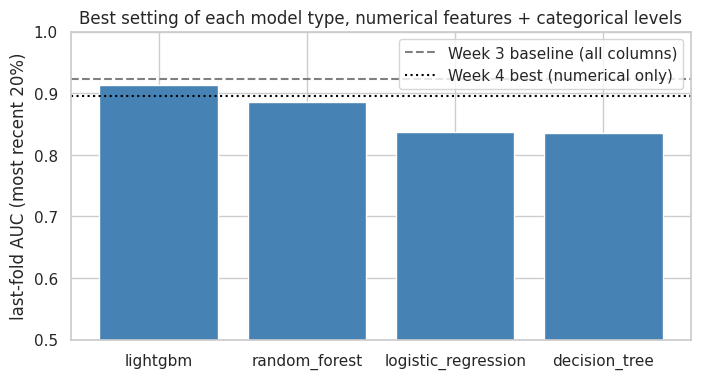

In [15]:
def best_of_each_model(results_tables):
    """The top row of each model type's tuning results, best model first."""
    best_rows = []
    for results in results_tables:
        best_rows.append(results.iloc[0])
    return pd.DataFrame(best_rows).sort_values('mean_auc', ascending=False).reset_index(drop=True)


comparison = best_of_each_model([logreg_results, tree_results, forest_results, lightgbm_results])
summary_columns = ['model', 'mean_auc', 'std_auc', 'last_fold_auc', 'fraud_caught_top_1pct', 'review_precision_top_1pct']
print(comparison[summary_columns].round(4).to_string(index=False))
print(f'\nLast-20% split references: Week 3 (all columns) {WEEK3_BASELINE_AUC}, Week 4 (numerical only) {WEEK4_BEST_AUC}')

plt.figure(figsize=(8, 4))
plt.bar(comparison['model'], comparison['last_fold_auc'], color='steelblue')
plt.axhline(WEEK3_BASELINE_AUC, linestyle='--', color='gray', label='Week 3 baseline (all columns)')
plt.axhline(WEEK4_BEST_AUC, linestyle=':', color='black', label='Week 4 best (numerical only)')
plt.ylim(0.5, 1.0)
plt.ylabel('last-fold AUC (most recent 20%)')
plt.title('Best setting of each model type, numerical features + categorical levels')
plt.legend()
plt.show()

### Best model and settings for the submission notebook

Copy these three values into the constants cell of `bm-fraud-categorical-submission`.

In [16]:
best = comparison.iloc[0]
best_trees = None
if best['model'] == 'lightgbm':
    best_trees = int(best['mean_trees'])

print(f"BEST_MODEL_NAME = '{best['model']}'")
print(f"BEST_PARAMS = {json.loads(best['params'])}")
print(f'BEST_N_ESTIMATORS = {best_trees}   # LightGBM only: average number of trees early stopping chose')

BEST_MODEL_NAME = 'lightgbm'
BEST_PARAMS = {'subsample': 0.8, 'reg_lambda': 5.0, 'num_leaves': 255, 'min_child_samples': 50, 'learning_rate': 0.02, 'colsample_bytree': 0.3}
BEST_N_ESTIMATORS = 418   # LightGBM only: average number of trees early stopping chose


### What tuning showed

- Best model type: **LightGBM**, mean AUC **0.9071**, last-fold AUC **0.9126** (Week 4: 0.8960, Week 3: 0.9227).
- Fraud caught reviewing the top 1%: **24.7%**, with **93.0%** of reviewed transactions being fraud.
- Logistic regression, decision tree and random forest best mean AUCs: **0.8447**, **0.8391**, **0.8824** (Week 4: 0.8317, 0.8351, 0.8691).
- What the categorical levels added compared with Week 4: every model type improved. LightGBM's last-fold AUC went up 0.017, which closes about 60% of the gap to Week 3. The top three LightGBM settings are within 0.0001 of each other, so more tuning probably won't help much. The rest of the gap is most likely `card1`: it has 13,553 values, and the 25 levels kept here cover only about 10% of transactions, while Week 3's LightGBM could split on all of them. That points to next week's customer-level and frequency features.